# alphagenome PyTorch local test
- replicate fig 4.b. from avesec et al 2026, using local alphagenome
- model is the PyTorch port ([alphagenome-pytorch](https://github.com/genomicsxai/alphagenome-pytorch))
- one-hot encoding and forward pass follow `examples/notebooks/alphagenome_pytorch_demo.ipynb`
- predictions for a known eQTL (chr. 22: 36201698: A>C) in GTEx colon (sigmoid) tissue (Fig. 4b) in Avsec et al 2026
- https://www.nature.com/articles/s41586-025-10014-0/figures/4
- UBERON:0001159
- everything plotted is **predicted** (no observed GTEx coverage)

In [ ]:
# This notebook installs its own packages with pip (torch, alphagenome-pytorch, ...).
# Keep the Gen3 software library (/apps, added to PYTHONPATH by `module load`) out of this kernel:
# otherwise its older packages are found first and shadow the pip-installed ones
# (e.g. "cannot import name 'sentinel' from 'typing_extensions'").
# Run this cell first, right after (re)starting the kernel.
import os, sys, site, importlib
os.environ["PYTHONPATH"] = ":".join(p for p in os.environ.get("PYTHONPATH", "").split(":")
                                    if p and not p.startswith("/apps/"))   # also applies to %pip
sys.path[:] = [p for p in sys.path if not p.startswith("/apps/")]
user_site = site.getusersitepackages()
if user_site not in sys.path:
    sys.path.insert(0, user_site)
# Forget packages already imported from the software library, so they are re-imported from pip -
# but never the ones the running kernel itself is built on (IPython, ipykernel, Jupyter, ...).
KERNEL_PACKAGES = {
    "IPython", "ipykernel", "ipython_pygments_lexers", "jupyter_client", "jupyter_core", "traitlets", "zmq",
    "tornado", "comm", "debugpy", "prompt_toolkit", "pygments", "jedi", "parso", "matplotlib_inline",
    "decorator", "stack_data", "executing", "asttokens", "pure_eval", "wcwidth", "platformdirs", "psutil",
    "nest_asyncio", "pexpect", "ptyprocess", "dateutil", "packaging",
}
for name, mod in list(sys.modules.items()):
    if name.split(".")[0] not in KERNEL_PACKAGES and (getattr(mod, "__file__", None) or "").startswith("/apps/"):
        del sys.modules[name]
importlib.invalidate_caches()

In [1]:
from IPython.display import clear_output

In [2]:
%pip install torch --user
clear_output()

In [3]:
%pip install alphagenome-pytorch pyfaidx alphagenome --user
clear_output()

### import libraries
- see https://github.com/genomicsxai/alphagenome-pytorch/blob/main/examples/notebooks/alphagenome_pytorch_demo.ipynb

In [4]:
import os
os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'
import numpy as np
import pandas as pd
import torch
import pyfaidx as _pyfaidx
import matplotlib.pyplot as plt
from types import SimpleNamespace

from alphagenome_pytorch import AlphaGenome

# visualization / annotation utilities
from alphagenome.data import genome, gene_annotation, transcript, track_data
from alphagenome.visualization import plot_components

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

PyTorch version: 2.14.1+cu130
CUDA available: True


### local model weights, fasta and track metadata

In [ ]:
import os

# All inputs are read from Aarti's shared folder (read-only for other users), nothing to download
INPUT_DIR = '/home/jovyan/shared/internal/per-user/aartiv@uchicago.edu/alphagenome_test'

# model_all_folds.safetensors available from https://huggingface.co/gtca/alphagenome_pytorch
MODEL_WEIGHTS_PATH  = f'{INPUT_DIR}/model_all_folds.safetensors'
# download from https://hgdownload.soe.ucsc.edu/goldenPath/hg38/bigZips/hg38.fa.gz
LOCAL_FASTA         = f'{INPUT_DIR}/hg38.fa'
# this comes from running extract_track_metadata.py on JAX model, see in scripts:
# https://github.com/genomicsxai/alphagenome-pytorch/tree/main/scripts
# run !python extract_track_metadata.py --output data/annotations/track_metadata.parquet
# JAX model is downloaded from kagglehub
# e.g. JAX_WEIGHTS_PATH = '~/.cache/kagglehub/models/google/alphagenome/jax/all_folds/1'
TRACK_METADATA_PATH = f'{INPUT_DIR}/track_metadata.parquet'   # folder with track_metadata_human.parquet

missing = [p for p in (MODEL_WEIGHTS_PATH, LOCAL_FASTA, TRACK_METADATA_PATH) if not os.path.exists(p)]
if missing:
    raise FileNotFoundError("Input files not found (is the shared folder available in this workspace?):\n  "
                            + "\n  ".join(missing))

# pyfaidx needs an index for hg38.fa (hg38.fa.fai). The shared folder is read-only for other users,
# so if the index is not there it is built once in the user's own folder instead.
FASTA_INDEX = LOCAL_FASTA + '.fai'
if not os.path.exists(FASTA_INDEX):
    os.makedirs(os.path.expanduser('~/pd/alphagenome_test'), exist_ok=True)
    FASTA_INDEX = os.path.expanduser('~/pd/alphagenome_test/hg38.fa.fai')

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

### load model

In [6]:
model = AlphaGenome.from_pretrained(MODEL_WEIGHTS_PATH)
model.to(device).eval()

print("Model loaded successfully!")

Model loaded successfully!


### number of parameters

In [8]:
n_total = sum(p.numel() for p in model.parameters())
print(f"Total:     {n_total:,}")

Total:     450,452,613


In [9]:
# extract REF and ALT sequences
_fasta  = _pyfaidx.Fasta(LOCAL_FASTA, indexname=FASTA_INDEX)
_chrom = 'chr22'
_pos_1b = 36201698       # 1-based
# 128 kb (2^17); must be a multiple of 2048. Full size is 1048576 (2^20)
# try 131,072 for T4 GPU
_seq_len = 131072        
_half   = _seq_len // 2
_start0 = _pos_1b - 1 - _half

ref_seq = str(_fasta[_chrom][_start0 : _start0 + _seq_len]).upper()
assert ref_seq[_half] == 'A', f"Expected REF='A', got '{ref_seq[_half]}'"
alt_seq = ref_seq[:_half] + 'C' + ref_seq[_half + 1:]
print(f'REF context: ...{ref_seq[_half-2:_half+3]}...')
print(f'ALT context: ...{alt_seq[_half-2:_half+3]}...')

REF context: ...TCACC...
ALT context: ...TCCCC...


In [10]:
# sequence string -> integer indices: 0=A, 1=C, 2=G, 3=T  (1, length)
ref_idx = np.array([['ACGT'.index(b) for b in ref_seq]])
alt_idx = np.array([['ACGT'.index(b) for b in alt_seq]])

# One-hot encode
dna_one_hot_ref = np.eye(4)[ref_idx]  # (1, length, 4)
dna_one_hot_alt = np.eye(4)[alt_idx]
dna_one_hot_ref = torch.tensor(dna_one_hot_ref, dtype=torch.float32).to(device)
dna_one_hot_alt = torch.tensor(dna_one_hot_alt, dtype=torch.float32).to(device)

# Organism index: 0 = human, 1 = mouse
organism_index = torch.tensor([0], dtype=torch.long).to(device)

print(f"Input shape: {dna_one_hot_ref.shape}")
print(f"Organism: Human (index={organism_index.item()})")
print(f'REF at variant: {dna_one_hot_ref[0, _half].cpu().numpy()}  (expect A=[1,0,0,0])')
print(f'ALT at variant: {dna_one_hot_alt[0, _half].cpu().numpy()}  (expect C=[0,1,0,0])')

Input shape: torch.Size([1, 131072, 4])
Organism: Human (index=0)
REF at variant: [1. 0. 0. 0.]  (expect A=[1,0,0,0])
ALT at variant: [0. 1. 0. 0.]  (expect C=[0,1,0,0])


In [11]:
# forward pass, as in the demo notebook:  outputs = model(dna_one_hot, organism_index)
# `heads=` (a documented forward() argument) skips heads we don't plot (contact maps, junctions, ...)
# see https://github.com/genomicsxai/alphagenome-pytorch/blob/72268c011d37cf2d387506493614952d85abe21b/src/alphagenome_pytorch/model.py#L770
_HEADS = ('rna_seq', 'cage', 'splice_sites')

with torch.no_grad():
    outputs_ref = model(dna_one_hot_ref, organism_index, heads=_HEADS)
    outputs_alt = model(dna_one_hot_alt, organism_index, heads=_HEADS)

print(f"Available output types: {list(outputs_ref.keys())}")
for name, out in outputs_ref.items():
    if isinstance(out, dict):
        for res, tensor in out.items():
            print(f"{name}[{res}]: {getattr(tensor, 'shape', type(tensor))}")

Available output types: ['cage', 'rna_seq', 'splice_sites']
cage[1]: torch.Size([1, 131072, 640])
cage[128]: torch.Size([1, 1024, 640])
rna_seq[1]: torch.Size([1, 131072, 768])
rna_seq[128]: torch.Size([1, 1024, 768])
splice_sites[logits]: torch.Size([1, 131072, 5])
splice_sites[probs]: torch.Size([1, 131072, 5])


In [12]:
%pip install --upgrade --force-reinstall pandas pyarrow --user
clear_output()

In [13]:
# PyTorch outputs -> TrackData => alphagenome plotting code
# PyTorch output tensors are (batch, length, tracks)
# track metadata maps track index -> (name, strand, ontology, ...)
_oh_interval = genome.Interval(chromosome='chr22', start=_start0, end=_start0 + _seq_len)

_meta_all = pd.read_parquet(TRACK_METADATA_PATH)
_meta_all = _meta_all[_meta_all['organism'] == 0].rename(columns={'track_name': 'name'})  # human

def _tracks_to_tdata(output_type, arr, ontology=None, strand='-'):
    # arr: (length, n_tracks) at 1 bp.  Keep tracks of `strand` (and `ontology` if given), like
    m = _meta_all[_meta_all['output_type'] == output_type]
    m = m[m['name'] != 'Padding']
    if ontology is not None:
        m = m[m['ontology_curie'] == ontology]
    m = m[m['strand'] == strand]
    if len(m) == 0:
        return None
    return track_data.TrackData(
        values=arr[:, m['track_index'].to_numpy()].astype(np.float32),
        metadata=m.reset_index(drop=True),
        resolution=1,
        interval=_oh_interval,
    )

def _to_output(outputs):
    rna  = outputs['rna_seq'][1][0].float().cpu().numpy()
    cage = outputs['cage'][1][0].float().cpu().numpy()
    spl  = outputs['splice_sites']['probs'][0].float().cpu().numpy()
    return SimpleNamespace(
        rna_seq      = _tracks_to_tdata('rna_seq', rna,  ontology='UBERON:0001159'),
        cage         = _tracks_to_tdata('cage',    cage, ontology='UBERON:0001159'),
        splice_sites = _tracks_to_tdata('splice_sites', spl),   # not tissue-specific
    )

# filter to negative strand (gene of interest is on '-')
_oh_ref_neg = _to_output(outputs_ref)
_oh_alt_neg = _to_output(outputs_alt)
print(_oh_ref_neg.rna_seq.metadata[['name', 'strand']])

                                name strand
0  UBERON:0001159 polyA plus RNA-seq      -
1       UBERON:0001159 total RNA-seq      -


In [14]:
# for plots
HG38_GTF_FEATHER = (
    'https://storage.googleapis.com/alphagenome/reference/gencode/'
    'hg38/gencode.v46.annotation.gtf.gz.feather'
)
gtf_path = HG38_GTF_FEATHER
gtf = pd.read_feather(gtf_path)

gtf_transcript = gene_annotation.filter_transcript_support_level(
    gene_annotation.filter_protein_coding(gtf), ['1']
)

# Extractor for identifying transcripts in a region.
transcript_extractor = transcript.TranscriptExtractor(gtf_transcript)


# define an extractor that fetches only the longest transcript per gene.
gtf_longest_transcript = gene_annotation.filter_to_longest_transcript(
    gtf_transcript
)
longest_transcript_extractor = transcript.TranscriptExtractor(
    gtf_longest_transcript
)

In [15]:
# plot params
_oh_variant  = genome.Variant(
    chromosome='chr22', position=36201698, reference_bases='A', alternate_bases='C')
_plot_kwargs = dict(
    interval=_oh_interval.resize(min(43008, _seq_len)),
    annotations=[plot_components.VariantAnnotation([_oh_variant])],
)

_track_specs = [
    (_oh_ref_neg.rna_seq,     _oh_alt_neg.rna_seq,     'RNA_SEQ',
     '{biosample_name} ({strand})\n{name}'),
    (_oh_ref_neg.cage,        _oh_alt_neg.cage,        'CAGE',
     '{biosample_name} ({strand})\n{name}'),
    (_oh_ref_neg.splice_sites, _oh_alt_neg.splice_sites, 'SPLICE_SITES',
     '{name} ({strand})'),
]

In [16]:
# overlay REF and ALT on the same axes (one panel per track, two colored lines)
_overlay_colors = {'REF': '#1f77b4', 'ALT': '#d62728'}

def _overlay_plot():
    comps = [plot_components.TranscriptAnnotation(
        longest_transcript_extractor.extract(_oh_interval))]
    for ref_td, alt_td, label, tmpl in _track_specs:
        if ref_td is None or ref_td.values.shape[-1] == 0:
            print(f'No {label} tracks for UBERON:0001159')
            continue
        comps.append(plot_components.OverlaidTracks(
            tdata={'REF': ref_td, 'ALT': alt_td},
            colors=_overlay_colors,
            ylabel_template=f'{label}: {tmpl}',
            order_tdata_by_mean=False,  # keep REF/ALT legend order fixed
            alpha=0.7,
        ))
    return comps

=== REF vs ALT overlay ===
No CAGE tracks for UBERON:0001159


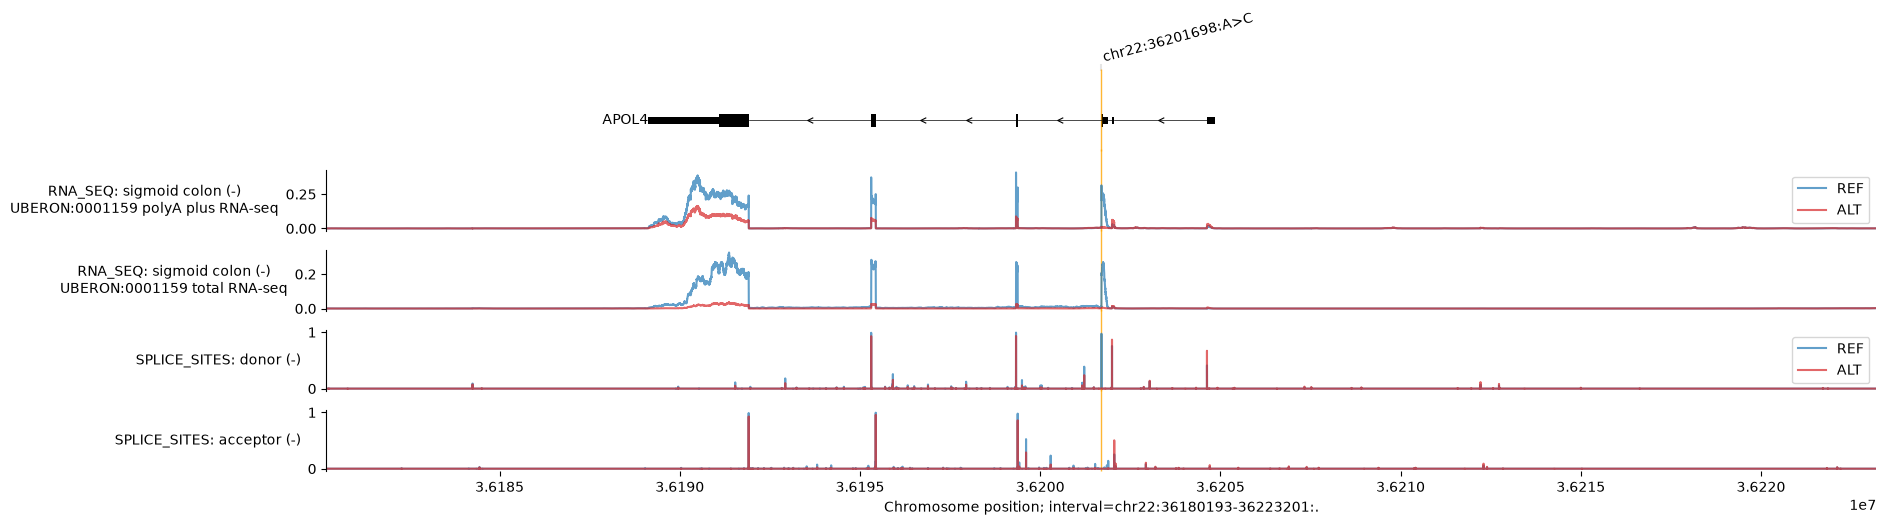

In [17]:
print('=== REF vs ALT overlay ===')
_ = plot_components.plot(components=_overlay_plot(), **_plot_kwargs)